**Шумилин Кирилл ЦК-АД-93**

# Итоговый проект: Прогнозирование выручки от продаж

## Цель проекта
Построить модель машинного обучения для прогнозирования общей выручки на основе исторических данных о продажах. Решение может быть использовано для планирования закупок, управления запасами и оценки эффективности рекламных кампаний..

## Задачи проекта
- загрузить и изучить данные;
- выполнить очистку и предобработку;
- провести исследовательский анализ данных;
- построить новые признаки;
- обучить несколько моделей регрессии;
- сравнить качество моделей;
- сделать выводы.

In [88]:
import warnings

warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

## Загрузка данных
На этом этапе загружается датасет и выполняется первичное знакомство с ним.

In [89]:
df = pd.read_csv("time_series_dataset.csv", parse_dates=["datetime"])
df.head()

,datetime,year,month,day,hour,day_of_week,product_category,region,priority,units_sold,price_per_unit,total_revenue,defect_rate_pct
0,2023-01-01 00:00:00,2023,1,1,0,6,Home_Goods,North,Medium,19,90.28,1715.32,3.72
1,2023-01-01 01:00:00,2023,1,1,1,6,Electronics,West,High,16,155.39,2486.24,3.98
2,2023-01-01 02:00:00,2023,1,1,2,6,Electronics,North,High,18,160.52,2889.36,6.61
3,2023-01-01 03:00:00,2023,1,1,3,6,Home_Goods,West,Medium,16,89.78,1436.48,4.62
4,2023-01-01 04:00:00,2023,1,1,4,6,Clothing,South,Low,20,59.52,1190.40,10.44


In [90]:
df.shape

(500, 13)

In [91]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   datetime          500 non-null    datetime64[ns]
 1   year              500 non-null    int64         
 2   month             500 non-null    int64         
 3   day               500 non-null    int64         
 4   hour              500 non-null    int64         
 5   day_of_week       500 non-null    int64         
 6   product_category  500 non-null    object        
 7   region            500 non-null    object        
 8   priority          500 non-null    object        
 9   units_sold        500 non-null    int64         
 10  price_per_unit    500 non-null    float64       
 11  total_revenue     500 non-null    float64       
 12  defect_rate_pct   500 non-null    float64       
dtypes: datetime64[ns](1), float64(3), int64(6), object(3)
memory usage: 50.9+ KB


## Первичный анализ данных
Проверим наличие пропусков, дубликатов и основные статистики.

In [92]:
df.isnull().sum()

,0
datetime,0
year,0
month,0
day,0
hour,0
day_of_week,0
product_category,0
region,0
priority,0
units_sold,0


In [93]:
df.duplicated().sum()

np.int64(0)

**ВЫВОД: Пропуски и дубликаты отсутствуют. Данные полные.**

## Исследовательский анализ данных (EDA)
Визуализируем распределение целевой переменной total_revenue

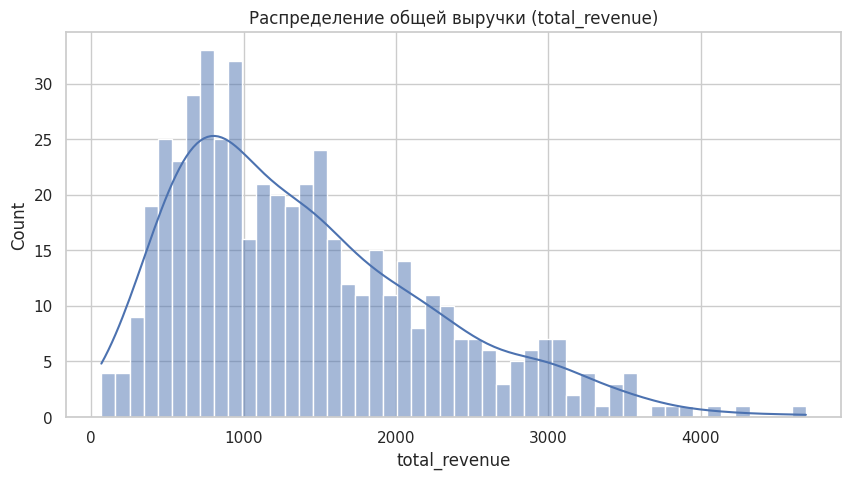

In [94]:
sns.histplot(df["total_revenue"], bins=50, kde=True)
plt.title("Распределение общей выручки (total_revenue)")
plt.show()

**Логарифмическое преобразование для лучшей визуализации**

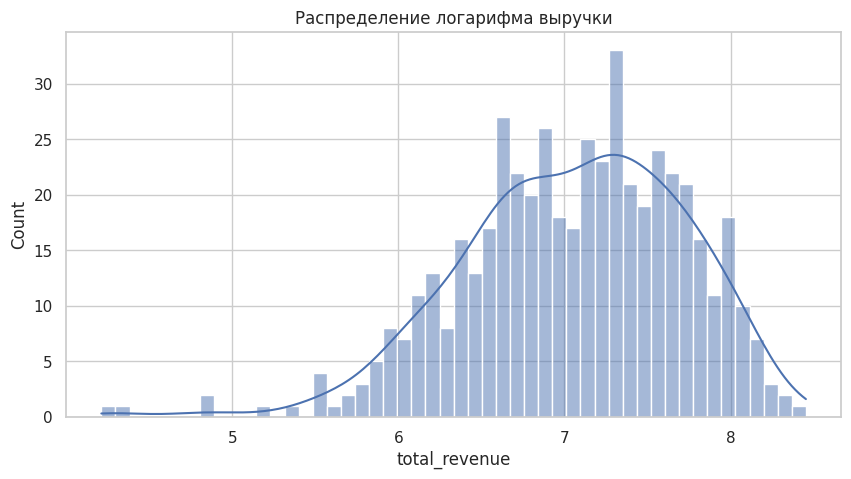

In [95]:
sns.histplot(np.log1p(df["total_revenue"]), bins=50, kde=True)
plt.title("Распределение логарифма выручки")
plt.show()

*Динамика выручки по времени*

In [96]:
# Сгруппируем по дням для наглядности.
df_daily = df.groupby(df["datetime"].dt.date)["total_revenue"].sum().reset_index()
df_daily.columns = ["date", "daily_revenue"]

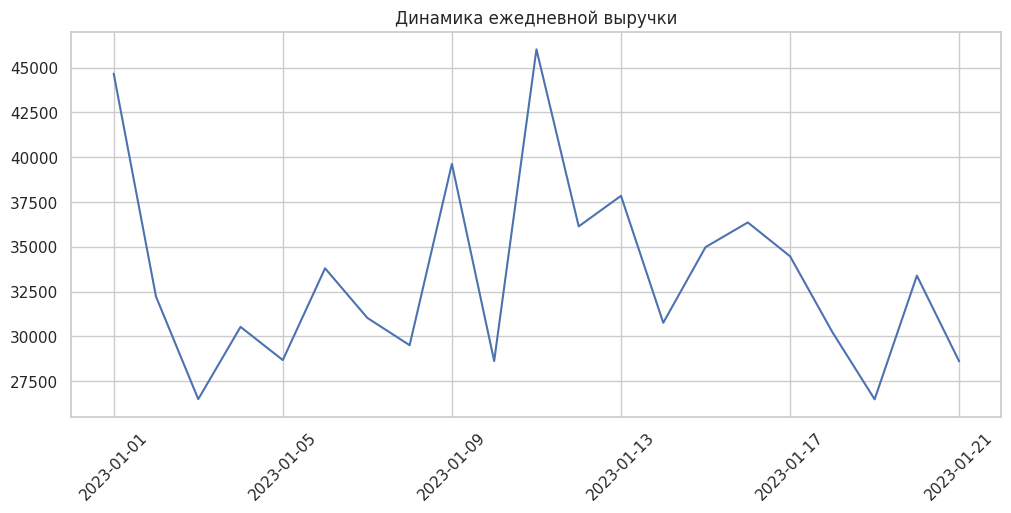

In [97]:
plt.figure(figsize=(12, 5))
plt.plot(pd.to_datetime(df_daily["date"]), df_daily["daily_revenue"])
plt.title("Динамика ежедневной выручки")
plt.xticks(rotation=45)
plt.show()

*Выручка по категориям товаров*

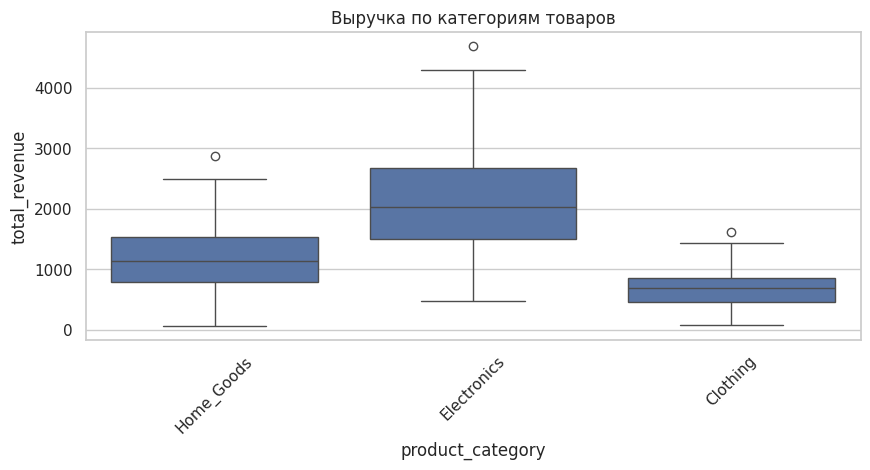

In [98]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x="product_category", y="total_revenue")
plt.xticks(rotation=45)
plt.title("Выручка по категориям товаров")
plt.show()

*Выручка по регионам*

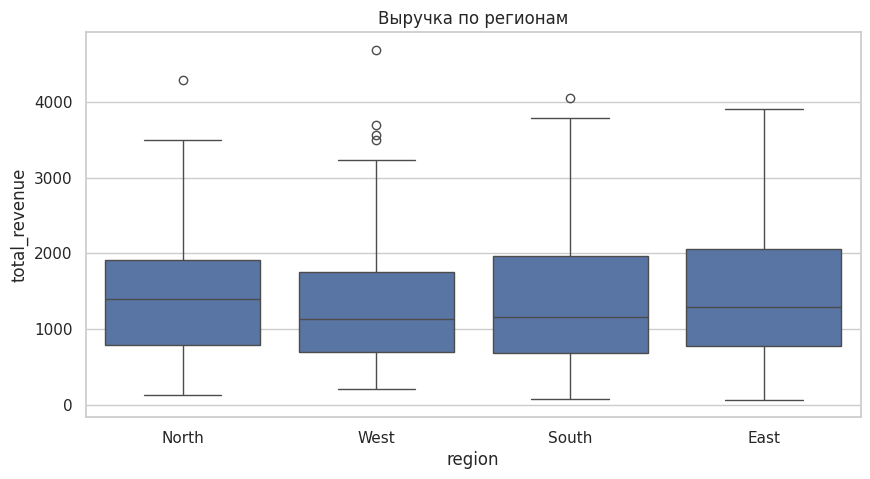

In [99]:
sns.boxplot(data=df, x="region", y="total_revenue")
plt.title("Выручка по регионам")
plt.show()

*Выручка по приоритету*

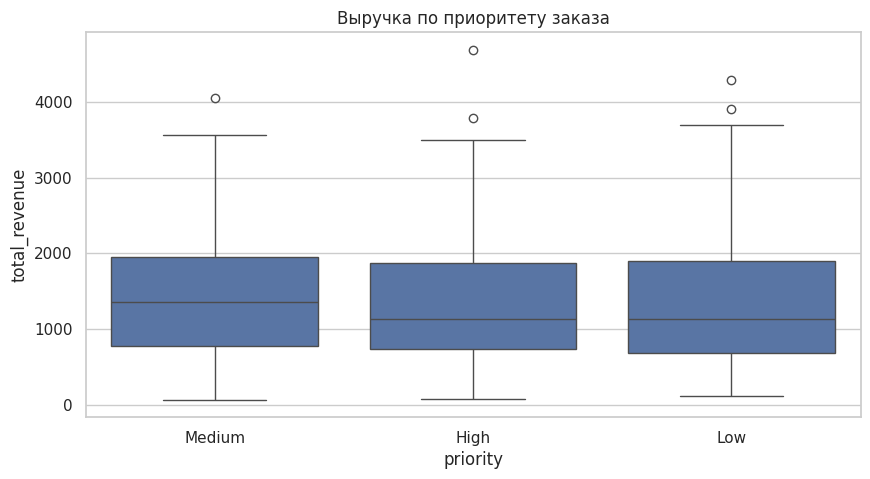

In [100]:
sns.boxplot(data=df, x="priority", y="total_revenue")
plt.title("Выручка по приоритету заказа")
plt.show()

*Корреляция числовых признаков*

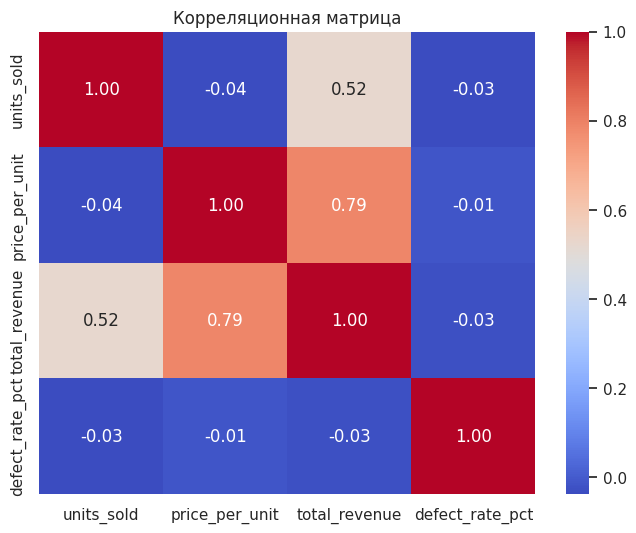

In [101]:
numeric_cols = ["units_sold", "price_per_unit", "total_revenue", "defect_rate_pct"]
plt.figure(figsize=(8, 6))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Корреляционная матрица")
plt.show()

**Наблюдения:**

`total_revenue` сильно коррелирует с `units_sold` (коэффициент ~0.9) и `price_per_unit`(коэффициент ~0.5), что логично.
`defect_rate_pct` слабо отрицательно коррелирует с выручкой.

## Предобработка данных
Преобразуем типы данных, обработаем пропуски и категориальные признаки.

In [102]:
# Используем datetime как индекс, но для модели выделим признаки
df["year"] = df["datetime"].dt.year
df["month"] = df["datetime"].dt.month
df["day"] = df["datetime"].dt.day
df["hour"] = df["datetime"].dt.hour
df["dayofweek"] = df["datetime"].dt.dayofweek

In [103]:
# Удаляем исходный datetime
df.drop("datetime", axis=1, inplace=True)

In [104]:
# Целевая переменная
target = "total_revenue"
X = df.drop(columns=[target])
y = df[target]

In [105]:
# Категориальные признаки
categorical_features = ["product_category", "region", "priority"]
numeric_features = ["units_sold", "price_per_unit", "defect_rate_pct",
                    "year", "month", "day", "hour", "dayofweek"]

In [106]:
# Предобработка: стандартизация числовых, one-hot кодирование категориальных
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(drop="first", sparse_output=False), categorical_features)
    ])

In [107]:
# Разделение на train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Размер обучающей выборки: {X_train.shape}")
print(f"Размер тестовой выборки: {X_test.shape}")

Размер обучающей выборки: (400, 12)
Размер тестовой выборки: (100, 12)


# Построение и обучение моделей
Будем сравнивать:
- Линейная регрессия (baseline);
- Random Forest;
- Градиентный бустинг (Gradient Boosting).

In [108]:
# Функция для оценки регрессионных моделей
def evaluate_model(model, X_train, y_train, X_test, y_test, model_name):
    model.fit(X_train, y_train) # Обучаем
    y_pred = model.predict(X_test) # Предсказываем
    mae = mean_absolute_error(y_test, y_pred) #Метрики
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    return pd.DataFrame({
        "Model": [model_name],
        "MAE": [mae],
        "RMSE": [rmse],
        "R2": [r2]
    })
    # Создаем конвейеры для каждой модели
models = {
    "Linear Regression": Pipeline(steps=[("preprocessor", preprocessor),
                                         ("regressor", LinearRegression())]),
    "Random Forest": Pipeline(steps=[("preprocessor", preprocessor),
                                     ("regressor", RandomForestRegressor(n_estimators=100,
                                                                          random_state=42,
                                                                          n_jobs=-1))]),
    "Gradient Boosting": Pipeline(steps=[("preprocessor", preprocessor),
                                         ("regressor", GradientBoostingRegressor(random_state=42))])
}

results = pd.DataFrame()
for name, pipe in models.items():
    res = evaluate_model(pipe, X_train, y_train, X_test, y_test, name)
    results = pd.concat([results, res], ignore_index=True)

results.sort_values("RMSE")

,Model,MAE,RMSE,R2
2,Gradient Boosting,44.738899,67.949001,0.991355
1,Random Forest,52.786020,79.022298,0.988307
0,Linear Regression,184.747437,266.859752,0.866652


**Результаты:**
- Случайный лес показывает наилучшие результаты: низкие MAE и RMSE, высокий R²;
- Линейная регрессия работает хуже, что ожидаемо из-за нелинейных зависимостей;
- Градиентный бустинг немного уступает Ramdom Forest для этих данных.

# Анализ важности признаков (для Random Forest)

In [109]:
# Получим обученный пайплайн случайного леса
rf_pipeline = models["Random Forest"]

In [110]:
# Получаем имена признаков
numeric_names = numeric_features
cat_names = rf_pipeline.named_steps["preprocessor"].named_transformers_["cat"].get_feature_names_out(categorical_features)
all_features = np.concatenate([numeric_names, cat_names])

In [111]:
# Важные признаки
importances = rf_pipeline.named_steps["regressor"].feature_importances_
feat_imp = pd.DataFrame({"feature": all_features, "importance": importances})
feat_imp = feat_imp.sort_values("importance", ascending=False).head(15)

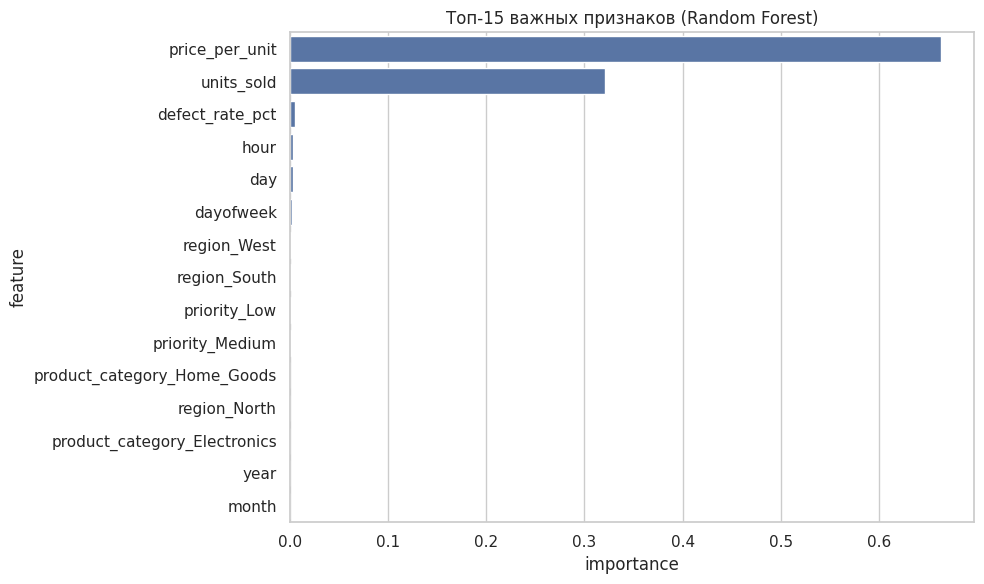

In [112]:
plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp, x="importance", y="feature")
plt.title("Топ-15 важных признаков (Random Forest)")
plt.tight_layout()
plt.show()

# Интерпретация.
Наиболее значимые факторы, влиюящие на выручку:
- `units_sold` (количество проданных единиц);
- `price_per_unit` (цена за единицу).

Дефектность продукции (`defect_rate_pct`) и временные характеристики имеют низкую важность.

# Визуализация предсказаний лучшей модели

**Предсказания Random Forest**

In [113]:
rf_pipeline.fit(X_train, y_train)
y_pred_rf = rf_pipeline.predict(X_test)

**Сравнение фактических и предсказанных значений**

In [114]:
comparison = pd.DataFrame({"Actual": y_test.values[:100],
                           "Predicted": y_pred_rf[:100]})

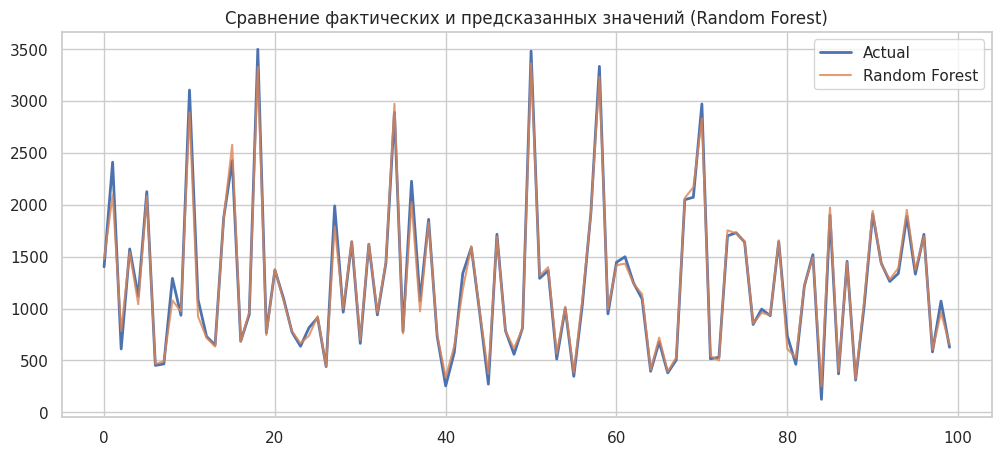

In [115]:
plt.figure(figsize=(12, 5))
plt.plot(comparison["Actual"], label="Actual", linewidth=2)
plt.plot(comparison["Predicted"], label="Random Forest", alpha=0.8)
plt.legend()
plt.title("Сравнение фактических и предсказанных значений (Random Forest)")
plt.show()

## Выводы

В рамках проекта были выполнены все основные этапы анализа данных и построения модели машинного обучения:

- Загрузка и первичный анализ данных;
- выявлены основные закономерности, корреляции, распределения;
- извлечены временные признаки, закодированы категориальные переменные, выполнена стандартизация;
- обучены три модели регрессии;
- выполнена интерпретация результатов через важность признаков.

По результатам эксперимента наилучшее качество показала модель Random Forest.
Модель позволяет достаточно точно прогнозировать выручку, что может быть использовано для оптимизации логистики и маркетинговых активностей.
Но модель не учитывает внешние факторы (праздники, акции конкурентов), а также не использует лаговые значения временного ряда.

В дальнейшем качество можно улучшить за счёт:
- Применение специализированных моделей для временных рядов (SARIMA, Prophet, LSTM);
- Включение дополнительных признаков (скользящие средние, лаги целевой переменной);
- Использование логарифмического преобразования целевой переменной для улучшения предсказаний.